# Segmentation

In [1]:
import platform
print(platform.system())

Windows


In [24]:
# Check os for specific code for path creation either on drive from colab or
# in local storage.
import os
import warnings

experiment_number = 1

if platform.system()=="Linux":
    from google.colab import drive
    # Mount Google Drive
    drive.mount('/content/drive', force_remount=False)

    experiment_base = f"/content/drive/MyDrive/Colab Notebooks/Module-CV/lightweight-UNET"


elif platform.system()=="Windows":
    experiment_base = f"./lightweight-UNET"

experiment_root = os.path.join(experiment_base, f"exp-{experiment_number}")

if os.path.exists(experiment_root):
  exps_index = [
      int(idx) if (idx := exp.rsplit('-', 1)[-1]).isnumeric() else -1
      for exp in os.listdir(experiment_base)
      if exp.startswith('exp')
  ]
  next_idx = max(exps_index) + 1
  new_experiment_root = os.path.join(experiment_base, f"exp-{next_idx}")
  warnings.warn(f"""
      Experiment root already exists: `{experiment_root}`.
      Update expermeriment number variable.
      Currecnt experiment indices are {exps_index}.
      Proceeding with index {next_idx} at {new_experiment_root}."""
  )
  experiment_root = new_experiment_root


C:\Users\rajba\AppData\Local\Temp\ipykernel_14768\3413797538.py:29: UserWarning: 
      Experiment root already exists: `./lightweight-UNET\exp-1`.
      Update expermeriment number variable.
      Currecnt experiment indices are [1, 2, 3, 4].
      Proceeding with index 5 at ./lightweight-UNET\exp-5.
  warnings.warn(f"""


In [25]:
experiment_root

'./lightweight-UNET\\exp-5'

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import keras

from keras import backend as K
from keras import layers
from PIL import Image

In [5]:
# from tensorflow.keras import mixed_precision
# mixed_precision.set_global_policy("float16")

https://huggingface.co/datasets/jonathan-roberts1/Ships-In-Satellite-Imagery

https://huggingface.co/datasets/IGNF/PASTIS-HD

https://huggingface.co/datasets/UrbanSyn/UrbanSyn#urbansyn-dataset

https://huggingface.co/datasets/LujianYao/HSSDataset

In [6]:


# # Define the path in Google Drive where you want to clone the dataset
# drive_path = '/content/drive/MyDrive/HSSDataset'

# # Create the directory if it doesn't exist
# if not os.path.exists(drive_path):
#     os.makedirs(drive_path)
#     print(f"Directory '{drive_path}' created.")

#     # Change the current working directory to the drive path
#     %cd {drive_path}

#     # Clone the dataset using git lfs
#     !git lfs install
#     # Ensure git lfs is installed (already done in a previous cell: pERe9L2nEHLy)
#     !git clone https://huggingface.co/datasets/LujianYao/HSSDataset .

#     print(f"Dataset cloned into '{drive_path}'")
# else:
#     print(f"Directory '{drive_path}' already exists. Skipping creation.")



In [7]:
# !git lfs install
# !git clone https://huggingface.co/datasets/LujianYao/HSSDataset

In [8]:
# arr = np.load("/content/drive/MyDrive/HSSDataset/HSS_VOC/npy_multichannel/10_frame_0001.npy")
# arr.shape

In [9]:
# arr = np.load("/content/drive/MyDrive/HSSDataset/HSS_VOC/npy_multichannel/11_frame_0433.npy")
# arr.shape

In [10]:
# len(os.listdir("/content/drive/MyDrive/HSSDataset/HSS_VOC/npy_multichannel"))

In [11]:
# dataset_root = "/content/drive/MyDrive/HSSDataset/HSS_VOC"
# hsi_data_dir = "npy_multichannel"
# splits = ['split/train.txt', 'split/val.txt', 'split/test.txt']
# total_files = 0

# for split in splits:
#     with open(os.path.join(dataset_root, split), 'r') as f:
#         # count number of files in each set
#         files = f.readlines()
#         print(f"Files in {split.rsplit('/', 1)[-1]}", n_files:=len(files))
#         total_files += n_files

#         # check existance of all files
#         for file in files:
#             file_path = os.path.join(dataset_root, hsi_data_dir, file.strip() + '.npy')
#             if not os.path.exists(file_path):
#                 print(f"Warning: File {file_path} does not exist")

#             # check dimension mismatch
#             shape = None
#             arr = np.load(file_path)
#             if shape is None:
#                 shape = arr.shape
#             else:
#                 if shape != arr.shape:
#                     print(f"Warning: File {file_path} has different shape")

# print(f"Total number of files: {total_files}")

In [12]:
# import os
# import shutil

# platform_name = platform.system()
# dataset_root = "/content/drive/MyDrive/HSSDataset/HSS_VOC" if platform_name == "Linux" else "./HSSDataset/HSS_VOC"
# hsi_data_dir = "npy_multichannel"
# mask_data_dir = "Mask"
# split_dir = "split"
# destination_root = "/content/HSSDataset_Splitted" if platform_name == "Linux" else "./HSSDataset_organized"

# splits = {
#     "train": "train.txt",
#     "val": "val.txt",
#     "test": "test.txt"
# }

# print("Starting dataset organization...")

# for split_name, split_file in splits.items():
#     split_filepath = os.path.join(dataset_root, split_dir, split_file)

#     dest_image_dir = os.path.join(destination_root, split_name, "images")
#     dest_mask_dir = os.path.join(destination_root, split_name, "masks")

#     os.makedirs(dest_image_dir, exist_ok=True)
#     os.makedirs(dest_mask_dir, exist_ok=True)

#     print(f"Processing {split_name} split using {split_filepath}")

#     with open(split_filepath, 'r') as f:
#         filenames = f.readlines()

#         for file_base in filenames:
#             file_base = file_base.strip() # Remove newline characters

#             # Source paths
#             src_image_path = os.path.join(dataset_root, hsi_data_dir, file_base + '.npy')
#             src_mask_path = os.path.join(dataset_root, mask_data_dir, file_base + '.png')

#             # Destination paths
#             dest_image_path = os.path.join(dest_image_dir, file_base + '.npy')
#             dest_mask_path = os.path.join(dest_mask_dir, file_base + '.png')

#             if os.path.exists(src_image_path) and os.path.exists(src_mask_path):
#                 shutil.copy(src_image_path, dest_image_path)
#                 shutil.copy(src_mask_path, dest_mask_path)
#             else:
#                 print(f"Warning: Skipping {file_base} - Image or mask not found: {src_image_path}, {src_mask_path}")

# print("Dataset organization complete!")

In [13]:
## This section is copying data from drive to colab for faster access of data
## No replication is required in local
import os
import shutil
import time

if platform.system()=="Linux":
    source_base_dir = "/content/drive/MyDrive/Colab Notebooks/Module-CV/HSSDataset"
    dest_base_dir = "/content/HSSDataset_Splitted"

    splits = ["train", "val", "test"]

    print(f"Starting data replication from {source_base_dir} to {dest_base_dir}...")

    for split_name in splits:
        source_image_dir = os.path.join(source_base_dir, split_name, "images")
        source_mask_dir = os.path.join(source_base_dir, split_name, "masks")

        dest_image_dir = os.path.join(dest_base_dir, split_name, "images")
        dest_mask_dir = os.path.join(dest_base_dir, split_name, "masks")

        os.makedirs(dest_image_dir, exist_ok=True)
        os.makedirs(dest_mask_dir, exist_ok=True)

        print(f"Processing {split_name} split...")

        # Copy images
        if os.path.exists(source_image_dir):
            image_files = os.listdir(source_image_dir)
            for img_file in image_files:
                shutil.copy(os.path.join(source_image_dir, img_file), dest_image_dir)
                time.sleep(0.01)
        else:
            print(f"Warning: Source image directory not found for {split_name}: {source_image_dir}")

        # Copy masks
        if os.path.exists(source_mask_dir):
            mask_files = os.listdir(source_mask_dir)
            for mask_file in mask_files:
                shutil.copy(os.path.join(source_mask_dir, mask_file), dest_mask_dir)
                time.sleep(0.01)
        else:
            print(f"Warning: Source mask directory not found for {split_name}: {source_mask_dir}")

    print("Data replication complete!")
else:
  print("No Data replication is required in local.")


No Data replication is required in local.


In [33]:
# Defining Dataset Class

import tensorflow as tf
import os

class HSSSegmentationDatasetTF:
    """
    A TensorFlow Dataset class for loading segmentation datasets from the HSSDataset structure.
    Expected structure: destination_root/[train|val|test]/images/image.npy
    and destination_root/[train|val|test]/masks/image.png (corresponding mask)
    """
    def __init__(
        self,
        dataset_root="/content/HSSDataset_Splitted", # Now points to the organized data
        image_dir="images", # Subdirectory inside split
        mask_dir="masks",   # Subdirectory inside split
        image_size=(512, 512),
        batch_size=32,
        split="train",
        img_ext=".npy",
        mask_ext=".png",
        img_channels=25, # Default to 25 channels for HSSDataset
        mask_channels=1
    ):
        self.dataset_root = dataset_root # This is now the organized dataset root
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.image_size = image_size
        self.batch_size = batch_size
        self.image_paths = []
        self.mask_paths = []
        self.split = split
        self.img_ext = img_ext
        self.mask_ext = mask_ext
        self.img_channels = img_channels
        self.mask_channels = mask_channels
        self._load_paths()

    def _load_paths(self):
        print(f"Inspecting dataset structure for segmentation at: {self.dataset_root}/{self.split}")

        current_split_images_path = os.path.join(self.dataset_root, self.split, self.image_dir)
        current_split_masks_path = os.path.join(self.dataset_root, self.split, self.mask_dir)

        if not os.path.isdir(current_split_images_path) or not os.path.isdir(current_split_masks_path):
            print(f"Error: Image or mask directory not found for split '{self.split}' at {self.dataset_root}")
            return

        # List all image files in the split's image directory
        image_filenames = sorted([f for f in os.listdir(current_split_images_path) if f.lower().endswith(self.img_ext)])

        for img_filename in image_filenames:
            base_filename = os.path.splitext(img_filename)[0]
            mask_filename = base_filename + self.mask_ext

            img_filepath = os.path.join(current_split_images_path, img_filename)
            mask_filepath = os.path.join(current_split_masks_path, mask_filename)

            if os.path.exists(img_filepath) and os.path.exists(mask_filepath):
                self.image_paths.append(img_filepath)
                self.mask_paths.append(mask_filepath)
            else:
                print(f"Warning: Skipping {base_filename} - Corresponding mask not found: {mask_filepath}")

        if not self.image_paths:
            print(f"Warning: No image-mask pairs found in '{current_split_images_path}' for split '{self.split}'.")
        else:
            print(f"Found {len(self.image_paths)} image-mask pairs for split '{self.split}'.")

    def _load_npy(self, path):
      arr = np.load(path.decode("utf-8"))
      return arr.astype(np.float32)[:-1, :-1, :]

    @tf.function
    def _parse_image_mask(self, image_path, mask_path):
        # Load hyperspectral .npy file
        image = tf.numpy_function(self._load_npy, [image_path], tf.float32)

        # Set static shape (important! needed for `tf.image.resize`)
        image.set_shape([None, None, self.img_channels])

        # Read and decode mask (as single channel grayscale image)
        mask = tf.io.read_file(mask_path)
        mask = tf.image.decode_png(mask, channels=self.mask_channels) # Ensure 1 channel (grayscale)
        resized_mask = tf.image.resize(
                    tf.cast(mask, tf.float32), # Cast to float for resize
                    (217, 409), # Target (height, width)
                    method=tf.image.ResizeMethod.NEAREST_NEIGHBOR
                )

        # Convert mask to binary (0 or 1) assuming any non-zero value is foreground
        mask = tf.cast(resized_mask > 0, tf.uint8) # Convert any non-zero value to 1, otherwise 0

        return image, mask[:-1, :-1, 0:1]

    def get_dataset(self, shuffle=False):
        if not self.image_paths:
            print("Dataset paths not loaded. Cannot create a TensorFlow dataset.")
            return None

        # Create a TensorFlow dataset from image and mask paths
        path_ds = tf.data.Dataset.from_tensor_slices((self.image_paths, self.mask_paths))
        dataset = path_ds.interleave(
            lambda img, mask: tf.data.Dataset.from_tensors((img, mask)),
            cycle_length=8,          # number of parallel readers
            num_parallel_calls=tf.data.AUTOTUNE
        )

        if shuffle:
            dataset = dataset.shuffle(buffer_size=len(self.image_paths)) # Shuffle the dataset

        # Map the parsing function to load and preprocess images and masks
        dataset = dataset.map(self._parse_image_mask, num_parallel_calls=tf.data.AUTOTUNE)

        # # Caching the dataset (consider if memory allows, especially for large datasets)
        # dataset = dataset.cache()

        dataset = dataset.batch(self.batch_size) # Batch the dataset
        dataset = dataset.prefetch(buffer_size=tf.data.AUTOTUNE) # Pre-fetch for performance
        return dataset

print("\n--- Loading HSSSegmentationDatasetTF ---")
if platform.system()=="Linux":
    dataset_root = "/content/HSSDataset_Splitted"
elif platform.system()=="Windows":
    dataset_root = "./HSSDataset_organized"
else:
  raise Exception("Platform not supported")

# Loading training data
train_segmentation_data = HSSSegmentationDatasetTF(
    dataset_root=dataset_root, # New root for organized data
    image_dir="images",
    mask_dir="masks",
    image_size=(216, 408),
    batch_size=16,
    split="train",
    img_channels=25,
    mask_channels=1
)

tf_train_dataset = train_segmentation_data.get_dataset(shuffle=True)
print("Type of train dataset: ", type(tf_train_dataset))

# Loading validation data
val_segmentation_data = HSSSegmentationDatasetTF(
    dataset_root=dataset_root,
    image_dir="images",
    mask_dir="masks",
    image_size=(216, 408),
    batch_size=16,
    split="val",
    img_channels=25,
    mask_channels=1
)

tf_val_dataset = val_segmentation_data.get_dataset(shuffle=False)
print("Type of validation dataset: ", type(tf_val_dataset))

# Loading test data
test_segmentation_data = HSSSegmentationDatasetTF(
    dataset_root=dataset_root,
    image_dir="images",
    mask_dir="masks",
    image_size=(216, 408),
    batch_size=16,
    split="test",
    img_channels=25,
    mask_channels=1
)

tf_test_dataset = test_segmentation_data.get_dataset(shuffle=False)
print("Type of test dataset: ", type(tf_test_dataset))


--- Loading HSSSegmentationDatasetTF ---
Inspecting dataset structure for segmentation at: ./HSSDataset_organized/train
Found 604 image-mask pairs for split 'train'.
Type of train dataset:  <class 'tensorflow.python.data.ops.prefetch_op._PrefetchDataset'>
Inspecting dataset structure for segmentation at: ./HSSDataset_organized/val
Found 201 image-mask pairs for split 'val'.
Type of validation dataset:  <class 'tensorflow.python.data.ops.prefetch_op._PrefetchDataset'>
Inspecting dataset structure for segmentation at: ./HSSDataset_organized/test
Found 202 image-mask pairs for split 'test'.
Type of test dataset:  <class 'tensorflow.python.data.ops.prefetch_op._PrefetchDataset'>


In [34]:
# Verification of dataset class

if tf_train_dataset:
    for image_batch, mask_batch in tf_train_dataset.take(1):
        print(f"Shape of one image batch from train dataset: {image_batch.shape}") # (batch_size, image_height, image_width, channels)
        print(f"Shape of one mask batch from train dataset: {mask_batch.shape}") # (batch_size, mask_height, mask_width, 1)
        print(f"Example mask pixel values (first image in batch, top-left corner):\n {mask_batch[0, :5, :5, 0].numpy()}")
        break
else:
    print("Failed to create TensorFlow training dataset. Check warnings above.")


if tf_val_dataset:
    for image_batch, mask_batch in tf_val_dataset.take(1):
        print(f"Shape of one image batch from validation dataset: {image_batch.shape}") # (batch_size, image_height, image_width, channels)
        print(f"Shape of one mask batch from validation dataset: {mask_batch.shape}") # (batch_size, mask_height, mask_width, 1)
        break
else:
    print("Failed to create TensorFlow validation dataset. Check warnings above.")

if tf_test_dataset:
    for image_batch, mask_batch in tf_test_dataset.take(1):
        print(f"Shape of one image batch from test dataset: {image_batch.shape}") # (batch_size, image_height, image_width, channels)
        print(f"Shape of one mask batch from test dataset: {mask_batch.shape}") # (batch_size, mask_height, mask_width, 1)
        break
else:
    print("Failed to create TensorFlow test dataset. Check warnings above.")

del tf_train_dataset, tf_val_dataset


Shape of one image batch from train dataset: (16, 216, 408, 25)
Shape of one mask batch from train dataset: (16, 216, 408, 1)
Example mask pixel values (first image in batch, top-left corner):
 [[0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]]
Shape of one image batch from validation dataset: (16, 216, 408, 25)
Shape of one mask batch from validation dataset: (16, 216, 408, 1)
Shape of one image batch from test dataset: (16, 216, 408, 25)
Shape of one mask batch from test dataset: (16, 216, 408, 1)


In [16]:
# Lightweight-UNet-Modelling
import tensorflow as tf
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, UpSampling2D,
    BatchNormalization, Activation, Concatenate
)
from tensorflow.keras.models import Model


def conv_block(x, filters, kernel_size=(3, 3)):
    x = Conv2D(filters, kernel_size, padding='same')(x)
    x = BatchNormalization()(x)
    x = Activation('relu')(x)
    return x


def justo_unet_simple(input_shape=(256, 256, 1)):
    inputs = Input(shape=input_shape)

    # ---------------- Encoder ----------------
    # Level 1
    c1 = conv_block(inputs, 6)
    p1 = MaxPooling2D((2, 2))(c1)

    # Level 2 (bottleneck)
    c2 = conv_block(p1, 12)
    p2 = MaxPooling2D((2, 2))(c2)

    # ---------------- Bottleneck ----------------
    c3 = conv_block(p2, 6)

    # ---------------- Decoder ----------------
    # Up 1
    u1 = UpSampling2D((2, 2))(c3)
    u1 = Concatenate()([u1, c2])
    c4 = conv_block(u1, 12)

    # Up 2
    u2 = UpSampling2D((2, 2))(c4)
    u2 = Concatenate()([u2, c1])
    c5 = conv_block(u2, 6)

    # ---------------- Output ----------------
    outputs = Conv2D(1, (3, 3), padding='same', activation='sigmoid')(c5)

    model = Model(inputs, outputs, name="2D_Justo_UNet_Simple_Binary")

    return model


# Build model
model = justo_unet_simple(input_shape=(216, 408, 25))
model.summary()

Model: "2D_Justo_UNet_Simple_Binary"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 216, 408,  │          0 │ -                 │
│ (InputLayer)        │ 25)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 216, 408,  │      1,356 │ input_layer[0][0] │
│                     │ 6)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 216, 408,  │         24 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 6)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 216, 408,  │          0 │ batch_normalizat… │
│ (Activation)        │ 6)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 108, 204,  │          0 │ activation[0][0]  │
│ (MaxPooling2D)      │ 6)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 108, 204,  │        660 │ max_pooling2d[0]… │
│                     │ 12)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 108, 204,  │         48 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 12)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 108, 204,  │          0 │ batch_normalizat… │
│ (Activation)        │ 12)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 54, 102,   │          0 │ activation_1[0][… │
│ (MaxPooling2D)      │ 12)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 54, 102,   │        654 │ max_pooling2d_1[… │
│                     │ 6)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 54, 102,   │         24 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 6)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 54, 102,   │          0 │ batch_normalizat… │
│ (Activation)        │ 6)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d       │ (None, 108, 204,  │          0 │ activation_2[0][… │
│ (UpSampling2D)      │ 6)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 108, 204,  │          0 │ up_sampling2d[0]… │
│ (Concatenate)       │ 18)               │            │ activation_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 108, 204,  │      1,956 │ concatenate[0][0] │
│                     │ 12)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 108, 204,  │         48 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 12)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 108, 204,  │          0 │ batch_normalizat

 Total params: 5,827 (22.76 KB)

 Trainable params: 5,743 (22.43 KB)

 Non-trainable params: 84 (336.00 B)

In [ ]:
# Defining custom loss functions

# def dice_loss(y_true, y_pred):
#     smooth = 1e-6

#     y_true = tf.cast(y_true, tf.float32)
#     y_pred = tf.cast(y_pred, tf.float32)

#     intersection = tf.reduce_sum(y_true * y_pred)
#     union = tf.reduce_sum(y_true) + tf.reduce_sum(y_pred)

#     dice = (2. * intersection + smooth) / (union + smooth)
#     return 1 - dice

def dice_loss(y_true, y_pred, smooth=1e-6):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)

    axes = (1, 2, 3)  # per-image

    intersection = tf.reduce_sum(y_true * y_pred, axis=axes)
    union = tf.reduce_sum(y_true, axis=axes) + tf.reduce_sum(y_pred, axis=axes)

    dice = (2. * intersection + smooth) / (union + smooth)
    return 1 - tf.reduce_mean(dice)

def lovasz_grad(gt_sorted):
    gts = tf.reduce_sum(gt_sorted)
    intersection = gts - tf.cumsum(gt_sorted)
    union = gts + tf.cumsum(1 - gt_sorted)
    jaccard = 1.0 - intersection / union
    jaccard = tf.concat([[jaccard[0]], jaccard[1:] - jaccard[:-1]], axis=0)
    return jaccard


def lovasz_hinge_flat(logits, labels):
    labels = tf.cast(labels, tf.float32)
    signs = 2. * labels - 1.
    errors = 1. - logits * signs

    errors_sorted, perm = tf.nn.top_k(errors, k=tf.shape(errors)[0])
    gt_sorted = tf.gather(labels, perm)

    grad = lovasz_grad(gt_sorted)
    loss = tf.tensordot(tf.nn.relu(errors_sorted), tf.stop_gradient(grad), axes=1)
    return loss


def lovasz_hinge_loss(y_true, y_pred):
    # Convert probabilities → logits
    y_pred = tf.clip_by_value(y_pred, 1e-6, 1 - 1e-6)
    logits = tf.math.log(y_pred / (1 - y_pred))

    y_true = tf.cast(y_true, tf.float32)

    logits = tf.reshape(logits, [-1])
    y_true = tf.reshape(y_true, [-1])

    return lovasz_hinge_flat(logits, y_true)

def bce_dice_loss(y_true, y_pred, alpha=0.3):
    bce = tf.reduce_mean(tf.keras.losses.binary_crossentropy(y_true, y_pred))
    d_loss = dice_loss(y_true, y_pred)

    return alpha * bce + (1 - alpha) * d_loss

def lovasz_dice_loss(y_true, y_pred):
    d_loss = dice_loss(y_true, y_pred)
    l_loss = lovasz_hinge_loss(y_true, y_pred)

    return 0.5 * d_loss + 0.5 * l_loss

In [18]:
# Defining the metrics

import tensorflow as tf

def f1_score(y_true, y_pred):
    y_pred = tf.cast(y_pred > 0.5, tf.float32)
    y_true = tf.cast(y_true, tf.float32)

    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])

    tp = tf.reduce_sum(y_true_f * y_pred_f)
    fp = tf.reduce_sum((1 - y_true_f) * y_pred_f)
    fn = tf.reduce_sum(y_true_f * (1 - y_pred_f))

    return (2 * tp + 1e-6) / (2 * tp + fp + fn + 1e-6)

def mean_iou(y_true, y_pred):
    y_pred = tf.cast(y_pred > 0.5, tf.float32)
    y_true = tf.cast(y_true, tf.float32)

    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])

    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    union = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) - intersection

    return (intersection + 1e-6) / (union + 1e-6)

def precision(y_true, y_pred):
    y_pred = tf.cast(y_pred > 0.5, tf.float32)
    y_true = tf.cast(y_true, tf.float32)

    tp = tf.reduce_sum(y_true * y_pred)
    fp = tf.reduce_sum((1 - y_true) * y_pred)

    return (tp + 1e-6) / (tp + fp + 1e-6)


def recall(y_true, y_pred):
    y_pred = tf.cast(y_pred > 0.5, tf.float32)
    y_true = tf.cast(y_true, tf.float32)

    tp = tf.reduce_sum(y_true * y_pred)
    fn = tf.reduce_sum(y_true * (1 - y_pred))

    return (tp + 1e-6) / (tp + fn + 1e-6)

In [27]:
import math


def lr_warmup_cosine_decay(epoch, lr, base_lr=1e-3, min_lr=1e-6, warmup_epochs=10, total_epochs=200):
    """
    Custom Scheduler: Linear Warmup followed by Cosine Decay.
    """
    if epoch < warmup_epochs:
        # Linear warmup: start at min_lr and reach base_lr
        lr = min_lr + (base_lr - min_lr) * (epoch / warmup_epochs)
    else:
        # Cosine decay: decay from base_lr to min_lr
        progress = (epoch - warmup_epochs) / (total_epochs - warmup_epochs)
        lr = min_lr + 0.5 * (base_lr - min_lr) * (1 + math.cos(math.pi * progress))
    
    return lr

def lr_warmup_exponential_decay(epoch, lr, base_lr=1e-3, min_lr=1e-6, warmup_epochs=10, total_epochs=200):
    """
    Custom Scheduler: Linear Warmup followed by Exponential Decay.
    """
    if epoch < warmup_epochs:
        # Linear warmup phase
        lr = min_lr + (base_lr - min_lr) * (epoch / warmup_epochs)
    else:
        # Calculate decay rate to hit min_lr exactly at total_epochs
        # Decay formula: lr = base_lr * (decay_rate ^ (epochs_since_warmup))
        decay_epochs = total_epochs - warmup_epochs
        decay_rate = (min_lr / base_lr) ** (1 / decay_epochs)
        lr = base_lr * (decay_rate ** (epoch - warmup_epochs))
        
    return lr

In [28]:
# Data Loader and Trainer class Implementation

import os
import tensorflow as tf
from tensorflow import keras
from keras import layers, models, callbacks
import numpy as np


class HSSDataLoader:
    def __init__(self, data_path, image_size, batch_size, split, img_channels, mask_channels):
        self.data_path = data_path
        self.image_size = image_size
        self.batch_size = batch_size
        self.split = split
        self.img_channels = img_channels
        self.mask_channels = mask_channels
        # Initialize HSSSegmentationDatasetTF here to get image_paths length
        self.dataset_loader = HSSSegmentationDatasetTF(
            dataset_root=self.data_path,
            image_dir="images",
            mask_dir="masks",
            image_size=self.image_size,
            batch_size=self.batch_size,
            split=self.split,
            img_channels=self.img_channels,
            mask_channels=self.mask_channels
        )

    def build_dataset(self, shuffle=True):
        return self.dataset_loader.get_dataset(shuffle=shuffle)

    def __len__(self):
        # Return the total number of samples for this split
        return len(self.dataset_loader.image_paths)


class SegmentationTrainer:
    """
    Trainer class for UNet segmentation model.

    Handles model creation, compilation, training, and evaluation.
    """
    def __init__(self, train_path, val_path, test_path, input_shape, num_classes, base_filters, learning_rate, batch_size):
        """
        Initialize the trainer.

        Args:
            train_path: Path to training dataset (e.g., /content/HSSDataset_Splitted)
            val_path: Path to validation dataset
            test_path: Path to test dataset
            input_shape: Input image shape (height, width, channels)
            num_classes: Number of segmentation classes
            base_filters: Base number of filters in UNet
            learning_rate: Learning rate for optimizer
            batch_size: Batch size for training
        """
        self.train_path = train_path
        self.val_path = val_path
        self.test_path = test_path
        self.input_shape = input_shape
        self.num_classes = num_classes
        self.base_filters = base_filters
        self.learning_rate = learning_rate
        self.batch_size = batch_size

        # Build model
        self.model = None
        self.history = None

    def build_model(self):
        """Build and compile the UNet model"""
        print("Building UNet model...")
        self.model = justo_unet_simple(input_shape=self.input_shape)

        # Explicitly build the model with a dummy input to handle the Resizing layer
        # This ensures the model knows its input shape before training
        # dummy_input = tf.ones((1,) + self.input_shape, dtype=tf.float32)
        # _ = self.model(dummy_input, training=False)

        # Compile model with appropriate loss for multi-class segmentation
        # Use SparseCategoricalCrossentropy for integer labels
        self.model.compile(
            optimizer=keras.optimizers.Adam(learning_rate=self.learning_rate),
            loss=bce_dice_loss,
            metrics=[
                'accuracy',
                f1_score,
                mean_iou,
                precision,
                recall
            ]
        )

        print("Model compiled successfully!")
        return self.model

    def prepare_datasets(self):
        """Create and prepare training and validation datasets"""
        print(f"Loading training data from: {self.train_path}")
        train_loader = HSSDataLoader(
            data_path=self.train_path,
            image_size=self.input_shape[:2],
            batch_size=self.batch_size,
            split="train",
            img_channels=self.input_shape[-1],
            mask_channels=1 # Assuming 1 channel for masks
        )
        train_dataset = train_loader.build_dataset(shuffle=True)

        print(f"Loading validation data from: {self.val_path}")
        val_loader = HSSDataLoader(
            data_path=self.val_path,
            image_size=self.input_shape[:2],
            batch_size=self.batch_size,
            split="val",
            img_channels=self.input_shape[-1],
            mask_channels=1 # Assuming 1 channel for masks
        )
        val_dataset = val_loader.build_dataset(shuffle=False)

        # Return both the datasets and the loaders so we can get their lengths
        return train_dataset, val_dataset, train_loader, val_loader

    def train(self, epochs=50, save_path="../models"):
        """
        Train the model.

        Args:
            epochs: Number of training epochs
            save_path: Path to save model checkpoints

        Returns:
            Training history
        """
        # Create save directory
        os.makedirs(save_path, exist_ok=True)

        # Build and compile model
        self.build_model()

        assert self.model is not None, "Model building failed. Cannot train."

        # Print model summary
        self.model.summary()

        # Prepare datasets
        train_dataset, val_dataset, train_loader, val_loader = self.prepare_datasets()

        # Define callbacks
        callback_list = [
            # Save best model based on validation loss
            callbacks.ModelCheckpoint(
                filepath=os.path.join(save_path, "best_model.keras"),
                monitor='val_mean_iou',
                save_best_only=True,
                mode='max',
                verbose=1
            ),
            # Early stopping
            callbacks.EarlyStopping(
                monitor='val_mean_iou',
                patience=10,
                restore_best_weights=True,
                mode='max',
                verbose=1
            ),
            callbacks.LearningRateScheduler(
                lambda epoch, lr: lr_warmup_exponential_decay(
                    epoch, lr, 
                    base_lr=self.learning_rate, 
                    warmup_epochs=10, 
                    total_epochs=200
                )
            ),
            # # Reduce learning rate on plateau
            # callbacks.ReduceLROnPlateau(
            #     monitor='val_mean_iou',
            #     factor=0.5,
            #     patience=5,
            #     min_lr=1e-7,
            #     mode='max',
            #     verbose=1
            # ),
            # TensorBoard logging
            callbacks.TensorBoard(
                log_dir=os.path.join(save_path, "logs_1")
            )
        ]

        print("\n" + "="*50)
        print("Starting training...")
        print(f"Epochs: {epochs}")
        print(f"Batch size: {self.batch_size}")
        print(f"Learning rate: {self.learning_rate}")
        print("="*50 + "\n")

        # Train the model
        self.history = self.model.fit(
            train_dataset,
            validation_data=val_dataset,
            epochs=epochs,
            callbacks=callback_list,
            verbose="auto"
        )

        # Save final model
        final_model_path = os.path.join(save_path, "final_model.keras")
        self.model.save(final_model_path)
        print(f"\nFinal model saved to: {final_model_path}")

        return self.history

    def evaluate(self):
        """
        Evaluate the model on test data.

        Returns:
            Evaluation metrics
        """
        if self.model is None:
            print("No model loaded. Building model...")
            self.build_model()

        assert self.model is not None, "Model building failed. Cannot evaluate."

        print(f"\nEvaluating on test data from: {self.test_path}")
        test_loader = HSSDataLoader(
            data_path=self.test_path,
            image_size=self.input_shape[:2],
            batch_size=self.batch_size,
            split="test",
            img_channels=self.input_shape[-1],
            mask_channels=1 # Assuming 1 channel for masks
        )
        test_dataset = test_loader.build_dataset(shuffle=False)

        test_steps_per_epoch = len(test_loader) // self.batch_size
        if len(test_loader) % self.batch_size != 0:
            test_steps_per_epoch += 1

        results = self.model.evaluate(test_dataset, steps=test_steps_per_epoch, verbose=1)

        print("\nTest Results:")
        print(f"  Loss: {results[0]:.4f}")
        print(f"  Accuracy: {results[1]:.4f}")
        print(f"  Mean IoU: {results[2]:.4f}")

        return results

    def predict(self, image):
        """
        Make predictions on a single image.

        Args:
            image: Input image tensor (H, W, C)

        Returns:
            Predicted segmentation mask
        """
        if self.model is None:
            raise ValueError("Model not built. Call build_model() first.")

        # Add batch dimension
        image = tf.expand_dims(image, axis=0)

        # Predict
        prediction = self.model.predict(image, verbose=0)

        # Get class with highest probability
        segmentation_map = tf.argmax(prediction, axis=-1)

        return segmentation_map[0].numpy()


def main():
    """Main training function"""
    if platform.system()=="Linux":
        dataset_root = "/content/HSSDataset_Splitted"
    elif platform.system()=="Windows":
        dataset_root = "./HSSDataset_organized"
    else:
      raise Exception("Platform not supported")

    # Configuration
    CONFIG = {
        'train_path': dataset_root,
        'val_path': dataset_root,
        'test_path': dataset_root,
        'input_shape': (216, 408, 25),  # Example shape, adjust as needed
        'num_classes': 1, # binary segmentation (background + object)
        'base_filters': 16, # Reduced base filters for quicker testing
        'learning_rate': 1e-3,
        'batch_size': 16, # Reduced batch size for quicker testing
        'epochs': 200, # Reduced epochs for quicker testing
        'save_path': f"{experiment_root}/models"
    }

    print("HSI Segmentation Training")
    print("="*50)
    print(f"Configuration:")
    for key, value in CONFIG.items():
        print(f"  {key}: {value}")
    print("="*50 + "\n")

    # Create trainer
    trainer = SegmentationTrainer(
        train_path=CONFIG['train_path'],
        val_path=CONFIG['val_path'],
        test_path=CONFIG['test_path'],
        input_shape=CONFIG['input_shape'],
        num_classes=CONFIG['num_classes'],
        base_filters=CONFIG['base_filters'],
        learning_rate=CONFIG['learning_rate'],
        batch_size=CONFIG['batch_size']
    )

    # Train the model
    history = trainer.train(
        epochs=CONFIG['epochs'],
        save_path=CONFIG['save_path']
    )

    # Evaluate on test set
    trainer.evaluate()

    print("\nTraining completed!")

    return history

history = main()

HSI Segmentation Training
Configuration:
  train_path: ./HSSDataset_organized
  val_path: ./HSSDataset_organized
  test_path: ./HSSDataset_organized
  input_shape: (216, 408, 25)
  num_classes: 1
  base_filters: 16
  learning_rate: 0.001
  batch_size: 16
  epochs: 200
  save_path: ./lightweight-UNET\exp-5/models

Building UNet model...
Model compiled successfully!


Model: "2D_Justo_UNet_Simple_Binary"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 216, 408,  │          0 │ -                 │
│ (InputLayer)        │ 25)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_12 (Conv2D)  │ (None, 216, 408,  │      1,356 │ input_layer_2[0]… │
│                     │ 6)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 216, 408,  │         24 │ conv2d_12[0][0]   │
│ (BatchNormalizatio… │ 6)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_10       │ (None, 216, 408,  │          0 │ batch_normalizat… │
│ (Activation)        │ 6)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_4     │ (None, 108, 204,  │          0 │ activation_10[0]… │
│ (MaxPooling2D)      │ 6)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_13 (Conv2D)  │ (None, 108, 204,  │        660 │ max_pooling2d_4[… │
│                     │ 12)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 108, 204,  │         48 │ conv2d_13[0][0]   │
│ (BatchNormalizatio… │ 12)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_11       │ (None, 108, 204,  │          0 │ batch_normalizat… │
│ (Activation)        │ 12)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_5     │ (None, 54, 102,   │          0 │ activation_11[0]… │
│ (MaxPooling2D)      │ 12)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_14 (Conv2D)  │ (None, 54, 102,   │        654 │ max_pooling2d_5[… │
│                     │ 6)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 54, 102,   │         24 │ conv2d_14[0][0]   │
│ (BatchNormalizatio… │ 6)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_12       │ (None, 54, 102,   │          0 │ batch_normalizat… │
│ (Activation)        │ 6)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_4     │ (None, 108, 204,  │          0 │ activation_12[0]… │
│ (UpSampling2D)      │ 6)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_4       │ (None, 108, 204,  │          0 │ up_sampling2d_4[… │
│ (Concatenate)       │ 18)               │            │ activation_11[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_15 (Conv2D)  │ (None, 108, 204,  │      1,956 │ concatenate_4[0]… │
│                     │ 12)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 108, 204,  │         48 │ conv2d_15[0][0]   │
│ (BatchNormalizatio… │ 12)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_13       │ (None, 108, 204,  │          0 │ batch_normalizat

 Total params: 5,827 (22.76 KB)

 Trainable params: 5,743 (22.43 KB)

 Non-trainable params: 84 (336.00 B)

Loading training data from: ./HSSDataset_organized
Inspecting dataset structure for segmentation at: ./HSSDataset_organized/train
Found 604 image-mask pairs for split 'train'.
Loading validation data from: ./HSSDataset_organized
Inspecting dataset structure for segmentation at: ./HSSDataset_organized/val
Found 201 image-mask pairs for split 'val'.

Starting training...
Epochs: 200
Batch size: 16
Learning rate: 0.001

Epoch 1/200
     38/Unknown 79s 2s/step - accuracy: 0.8963 - f1_score: 0.0192 - loss: 0.8374 - mean_iou: 0.0097 - precision: 0.0109 - recall: 0.0870
Epoch 1: val_mean_iou improved from None to 0.00014, saving model to ./lightweight-UNET\exp-5/models\best_model.keras

Epoch 1: finished saving model to ./lightweight-UNET\exp-5/models\best_model.keras
38/38 ━━━━━━━━━━━━━━━━━━━━ 90s 2s/step - accuracy: 0.8962 - f1_score: 0.0174 - loss: 0.8378 - mean_iou: 0.0088 - precision: 0.0098 - recall: 0.0827 - val_accuracy: 0.9806 - val_f1_score: 2.8498e-04 - val_loss: 0.8106 - val_mean_

Plotting training history...
Saving plots to: ./lightweight-UNET\exp-5/learning-curves


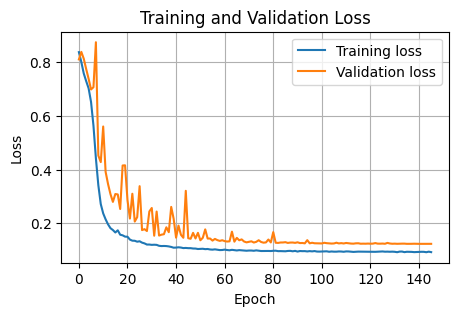

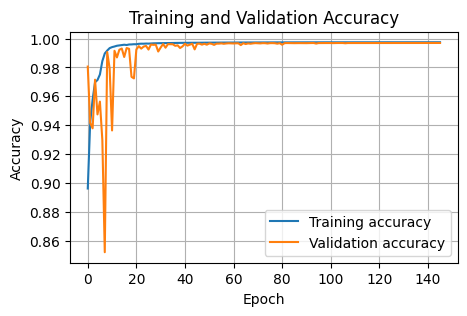

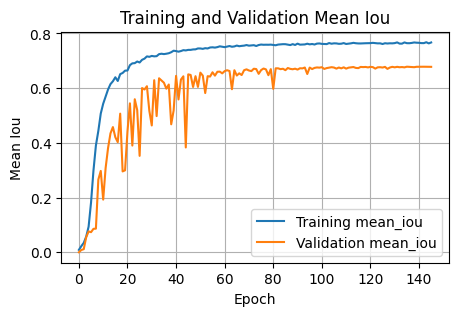

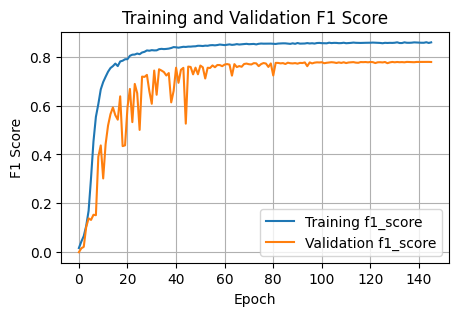

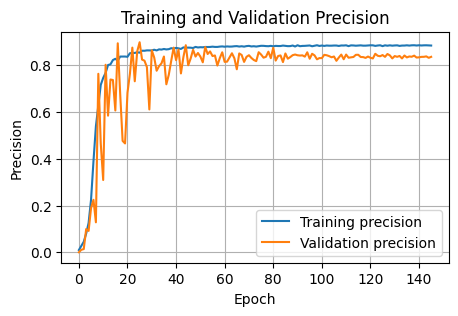

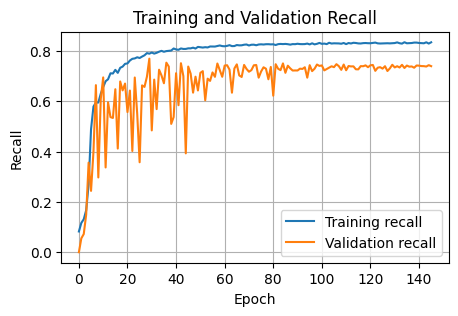

In [29]:
import matplotlib.pyplot as plt
import os

def plot_metrics(history, save_dir=None):
    """Plots training and validation metrics from a Keras history object.
    Optionally saves the plots to a specified directory.
    """
    metrics = ['loss', 'accuracy', 'mean_iou', 'f1_score', 'precision', 'recall']

    if save_dir:
        os.makedirs(save_dir, exist_ok=True)
        print(f"Saving plots to: {save_dir}")

    for metric in metrics:
        plt.figure(figsize=(5, 3))
        plt.plot(history.history[metric], label=f'Training {metric}')
        val_metric = f'val_{metric}'
        if val_metric in history.history:
            plt.plot(history.history[val_metric], label=f'Validation {metric}')
        plt.title(f'Training and Validation {metric.replace("_", " ").title()}')
        plt.xlabel('Epoch')
        plt.ylabel(metric.replace("_", " ").title())
        plt.legend()
        plt.grid(True)

        if save_dir:
            plot_filename = f'{metric}_curve.png'
            plt.savefig(os.path.join(save_dir, plot_filename))
        #     plt.close() # Close the plot to free memory
        # else:
        plt.show()

# Assuming 'history' object is available from the previous training run
if 'history' in locals() and history is not None:
    print("Plotting training history...")
    save_curves_path = f'{experiment_root}/learning-curves'
    plot_metrics(history, save_dir=save_curves_path)
else:
    print("Error: Training history not found. Please ensure the model has been trained.")


Model loaded successfully from ./lightweight-UNET\exp-5/models/best_model.keras
Inspecting dataset structure for segmentation at: ./HSSDataset_organized/test
Found 202 image-mask pairs for split 'test'.
Created test_dataset with batch_size=1 for plotting.


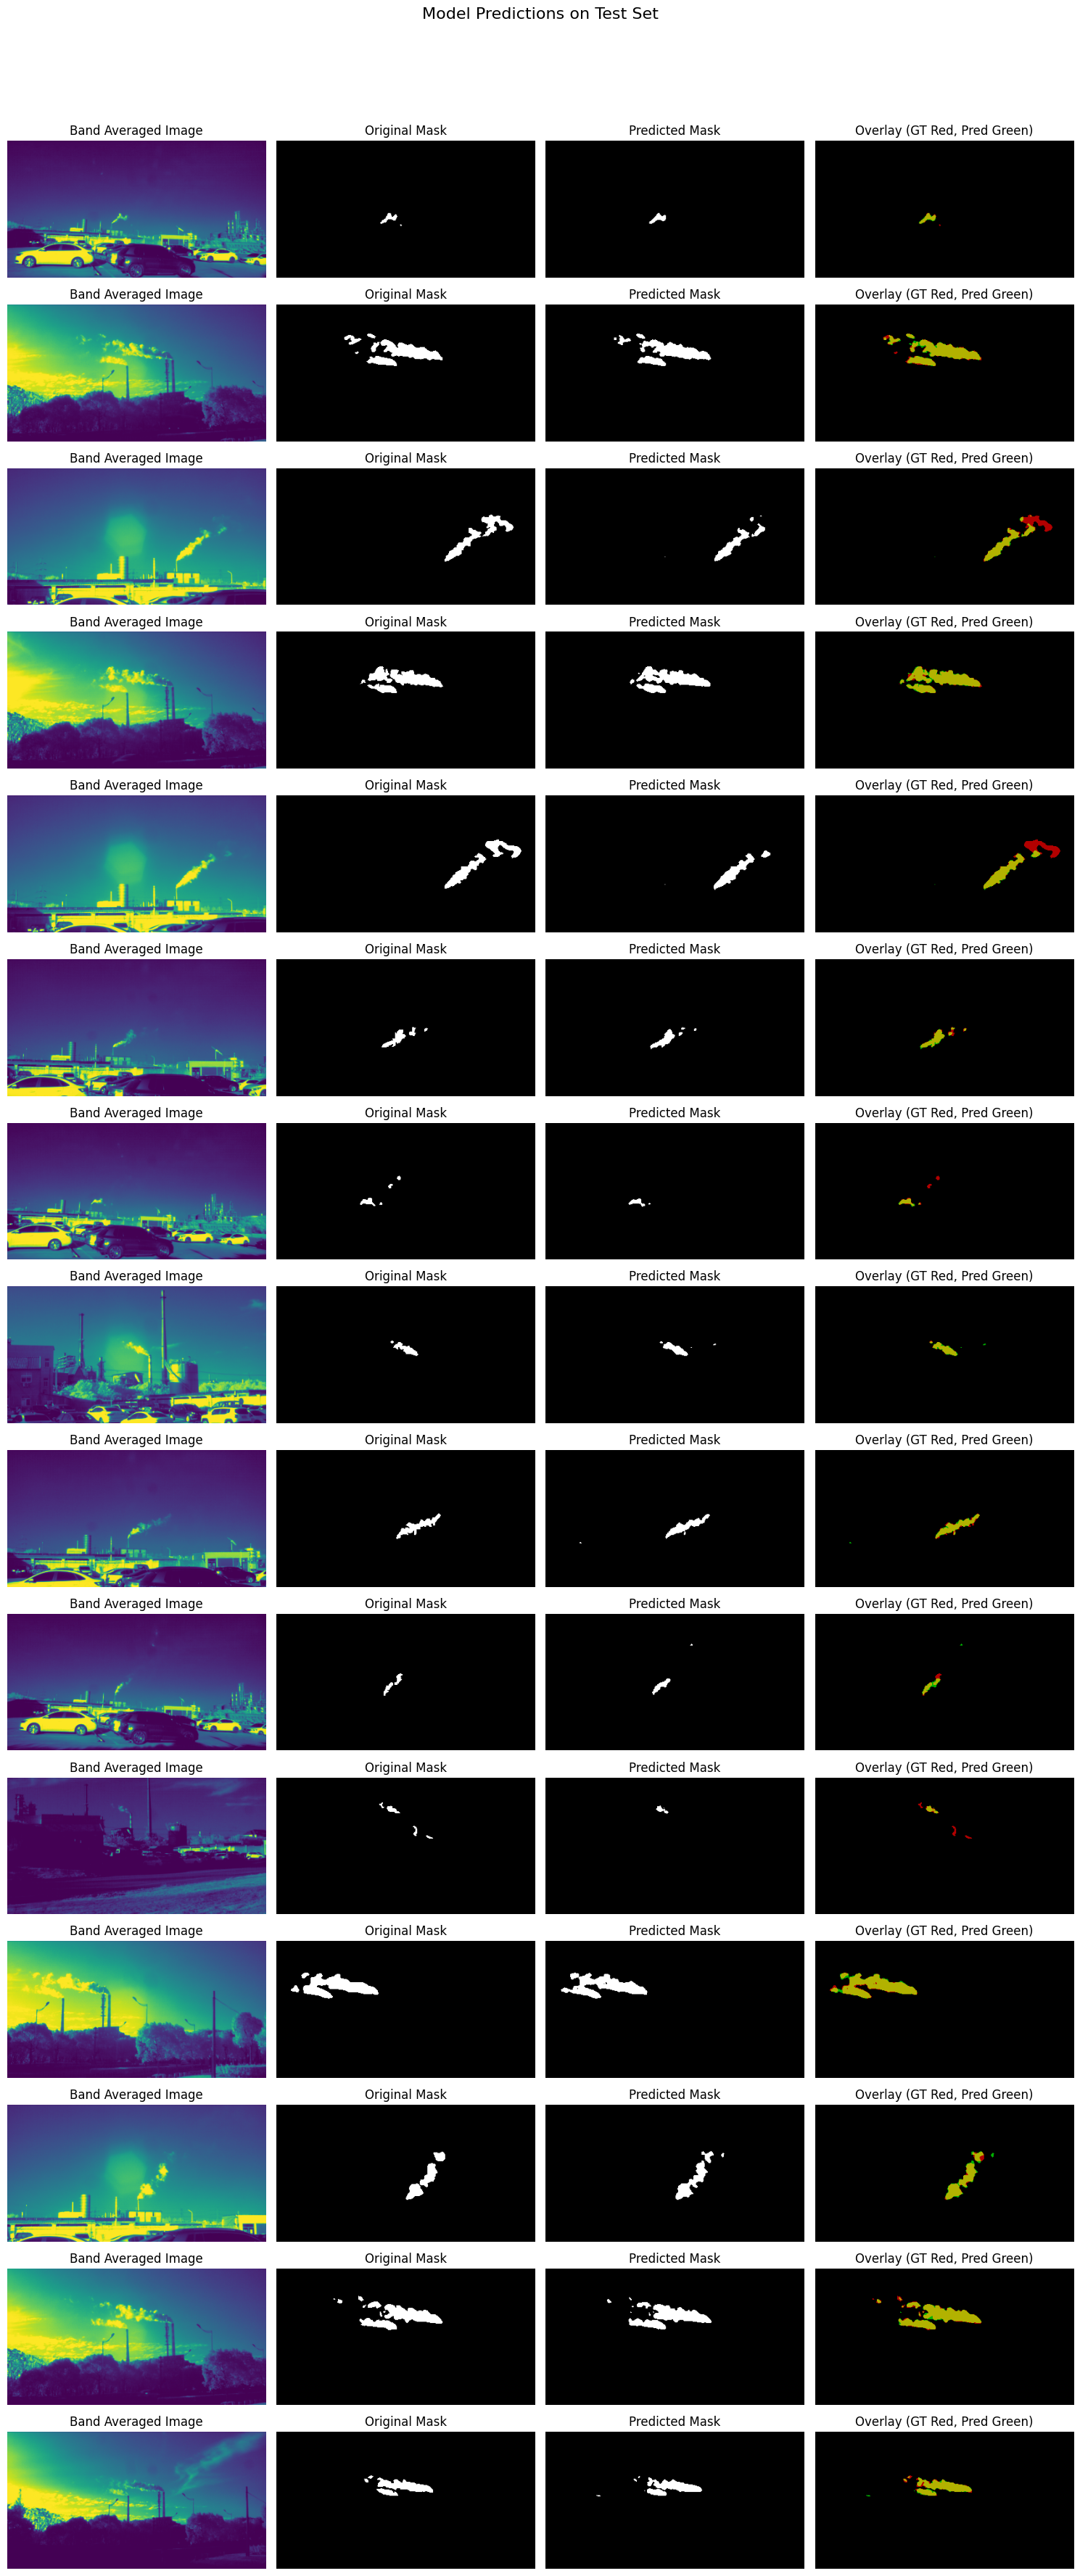

In [49]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os
import random

# Ensure custom objects (loss and metrics) are available for model loading.
# Defining them here again for clarity and robustness, in case this cell is run independently.

def dice_loss(y_true, y_pred):
    smooth = 1e-6
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)
    intersection = tf.reduce_sum(y_true * y_pred)
    union = tf.reduce_sum(y_true) + tf.reduce_sum(y_pred)
    dice = (2. * intersection + smooth) / (union + smooth)
    return 1 - dice

def bce_dice_loss(y_true, y_pred, alpha=0.3):
    bce = tf.reduce_mean(tf.keras.losses.binary_crossentropy(y_true, y_pred))
    d_loss = dice_loss(y_true, y_pred)
    return alpha * bce + (1 - alpha) * d_loss

def f1_score(y_true, y_pred):
    y_pred = tf.cast(y_pred > 0.5, tf.float32)
    y_true = tf.cast(y_true, tf.float32)
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])
    tp = tf.reduce_sum(y_true_f * y_pred_f)
    fp = tf.reduce_sum((1 - y_true_f) * y_pred_f)
    fn = tf.reduce_sum(y_true_f * (1 - y_pred_f))
    return (2 * tp + 1e-6) / (2 * tp + fp + fn + 1e-6)

def mean_iou(y_true, y_pred):
    y_pred = tf.cast(y_pred > 0.5, tf.float32)
    y_true = tf.cast(y_true, tf.float32)
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    union = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) - intersection
    return (intersection + 1e-6) / (union + 1e-6)

def precision(y_true, y_pred):
    y_pred = tf.cast(y_pred > 0.5, tf.float32)
    y_true = tf.cast(y_true, tf.float32)
    tp = tf.reduce_sum(y_true * y_pred)
    fp = tf.reduce_sum((1 - y_true) * y_pred)
    return (tp + 1e-6) / (tp + fp + 1e-6)

def recall(y_true, y_pred):
    y_pred = tf.cast(y_pred > 0.5, tf.float32)
    y_true = tf.cast(y_true, tf.float32)
    tp = tf.reduce_sum(y_true * y_pred)
    fn = tf.reduce_sum(y_true * (1 - y_pred))
    return (tp + 1e-6) / (tp + fn + 1e-6)


# 1. Load the saved best model
model_path = f"{experiment_root}/models/best_model.keras"

custom_objects = {
    'bce_dice_loss': bce_dice_loss,
    'f1_score': f1_score,
    'mean_iou': mean_iou,
    'precision': precision,
    'recall': recall
}

try:
    loaded_model = tf.keras.models.load_model(model_path, custom_objects=custom_objects)
    print(f"Model loaded successfully from {model_path}")
except Exception as e:
    print(f"Error loading model: {e}")
    loaded_model = None

if loaded_model:
    # 2. Get random images from the test set
    # Always create a new test_dataset with batch_size=1 for individual predictions
    test_segmentation_data_for_plot = HSSSegmentationDatasetTF(
        dataset_root=dataset_root,
        image_dir="images",
        mask_dir="masks",
        image_size=(216, 408), # Ensure this matches training input_shape
        batch_size=1, # Use batch size 1 for individual prediction and plotting
        split="test",
        img_channels=25,
        mask_channels=1
    )
    tf_test_dataset_for_plot = test_segmentation_data_for_plot.get_dataset(shuffle=True)
    print("Created test_dataset with batch_size=1 for plotting.")

    # Collect a few samples to pick from
    sample_images = []
    sample_masks = []
    for img_batch, msk_batch in tf_test_dataset_for_plot.take(50): # Take 50 samples to choose 5 random from
        # img_batch now has shape (1, H, W, C), so squeeze will result in (H, W, C)
        sample_images.append(img_batch.numpy().squeeze())
        sample_masks.append(msk_batch.numpy().squeeze())  # Remove batch dim

    k = 15
    if len(sample_images) < k:
        print(f"Not enough samples in test set ({len(sample_images)} found). Cannot plot {k} random images.")
    else:
        # Choose 5 random indices
        random_indices = random.sample(range(len(sample_images)), k)

        plt.figure(figsize=(15, 2.5 * k)) # k rows for k samples, 4 units height per row
        plt.suptitle("Model Predictions on Test Set", fontsize=16)

        for i, idx in enumerate(random_indices):
            original_image = sample_images[idx]
            original_mask = sample_masks[idx]

            # 3. Make prediction
            # Add batch dimension for prediction, as model expects (batch_size, H, W, C)
            input_image_for_pred = np.expand_dims(original_image, axis=0)
            predicted_mask_raw = loaded_model.predict(input_image_for_pred, verbose=0)
            # Threshold the raw prediction at 0.5 and convert to binary mask
            predicted_mask = (predicted_mask_raw.squeeze() > 0.5).astype(np.uint8)

            # Plotting for each random image in a 2x2 grid
            # 1. Band Averaged Image (mean across channels for visualization)
            ax = plt.subplot(k, 4, i * 4 + 1)
            band_averaged_image = np.mean(original_image, axis=-1)
            ax.imshow(band_averaged_image, cmap="viridis")
            ax.set_title("Band Averaged Image")
            ax.axis('off')

            # 2. Original Mask
            ax = plt.subplot(k, 4, i * 4 + 2)
            ax.imshow(original_mask, cmap='gray')
            ax.set_title("Original Mask")
            ax.axis('off')

            # 3. Predicted Mask
            ax = plt.subplot(k, 4, i * 4 + 3)
            ax.imshow(predicted_mask, cmap='gray')
            ax.set_title("Predicted Mask")
            ax.axis('off')

            # 4. Overlayed Mask (Ground Truth in Red, Prediction in Green)
            ax = plt.subplot(k, 4, i * 4 + 4)
            overlay_image = np.zeros((original_mask.shape[0], original_mask.shape[1], 3), dtype=np.float32)
            overlay_image[:, :, 0] = original_mask * 0.7 # Red channel for original mask
            overlay_image[:, :, 1] = predicted_mask * 0.7 # Green channel for predicted mask
            # Yellow where both are present (overlap)
            ax.imshow(overlay_image)
            ax.set_title("Overlay (GT Red, Pred Green)")
            ax.axis('off')

        plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to prevent title overlap
        plt.show()
